# Chapitre 3 - Cours 2 : SSTables, arbres LSM et filtres de Bloom

Ce notebook couvre la section *SSTables and LSM-Trees* : ses sous-sections
*Constructing and maintaining SSTables*, *Making an LSM-tree out of SSTables* et
*Performance optimizations* (filtres de Bloom, compaction par paliers de taille et par
niveaux). Nous construisons pas à pas un moteur LSM complet (`S.LSMTree`) et mesurons
ses amplifications d'écriture, de lecture et d'espace.

**Plan.**

1. Les SSTables : des segments triés, un index épars, des blocs compressibles.
2. Construire des SSTables : memtable, écriture sur disque et journal de reprise (WAL).
3. Fusionner des segments : le tri fusion et les tombstones.
4. Les filtres de Bloom : théorie, mesure et effet sur les lectures.
5. Les stratégies de compaction : par paliers de taille ou par niveaux.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Les SSTables (section *SSTables and LSM-Trees*)

**Idée.** Gardons des segments immuables, mais exigeons que chacun soit **trié par clé**
et ne contienne chaque clé **qu'une fois**. On appelle ce format une *Sorted String
Table*, ou **SSTable**. Le tri change tout :

- plus besoin de garder **toutes** les clés en mémoire : on découpe le fichier en
  **blocs** de quelques Kio et on ne retient que la **première clé de chaque bloc**. Cet
  index qui ne contient qu'une partie des clés est dit **épars** (*sparse*). Pour
  chercher une clé absente de l'index, on trouve les deux clés de l'index qui
  l'encadrent, on saute au début du bloc et on le parcourt ;
- chaque bloc peut être **compressé** : moins d'espace disque et moins de bande
  passante d'E/S, au prix d'un peu de CPU ;
- les requêtes **par intervalle** deviennent naturelles (les clés sont dans l'ordre).

In [2]:
items = [(S.kv_key(i), S.kv_value(i, size=100)) for i in range(0, 60_000, 3)]
sst = S.SSTable(items, block_bytes=4096)
st = {}
found, val = sst.get(S.kv_key(30_000), st)
print(f"{len(sst)} clés ; {len(sst.blocks)} blocs de 4 Kio ; index épars de {len(sst.sparse_index)} clés")
print("recherche de user00030000 :", found, "| blocs lus :", st["blocks_read"])
print("deux entrées de l'index qui l'encadrent :",
      sst.sparse_index[np.searchsorted(sst.sparse_index, S.kv_key(30_000), side="right") - 1],
      "<= clé <", sst.sparse_index[np.searchsorted(sst.sparse_index, S.kv_key(30_000), side="right")])

20000 clés ; 607 blocs de 4 Kio ; index épars de 607 clés
recherche de user00030000 : True | blocs lus : 1
deux entrées de l'index qui l'encadrent : user00029997 <= clé < user00030096


Le schéma ci-dessous montre la structure d'une SSTable telle que nous l'avons
implémentée : des blocs de données triés, un index épars (première clé de chaque bloc),
un filtre de Bloom (section 4).

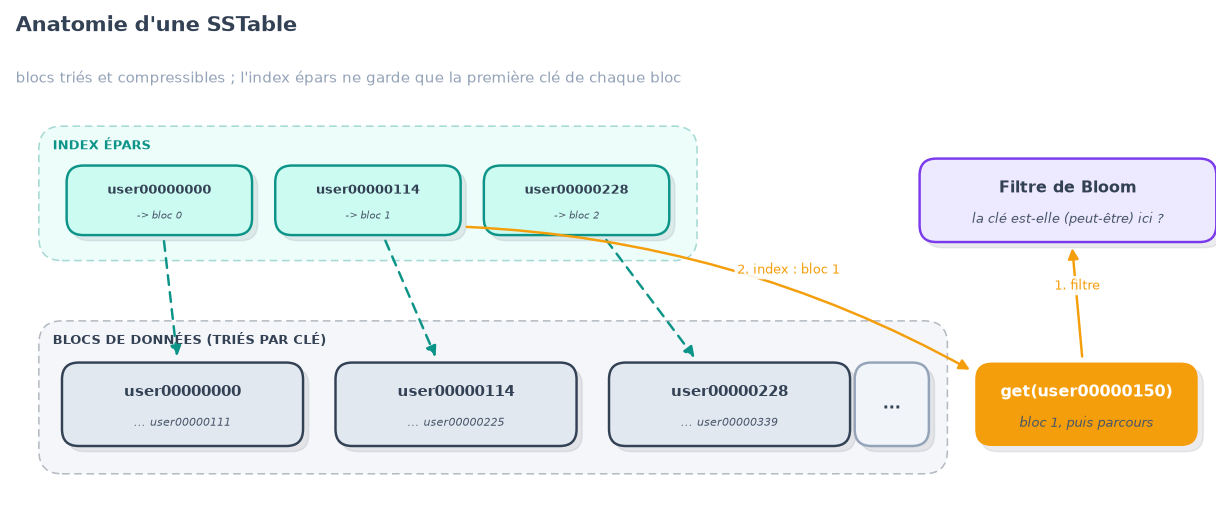

In [3]:
d = Diagram(13, 4.3, title="Anatomie d'une SSTable",
            subtitle="blocs triés et compressibles ; l'index épars ne garde que la première clé de chaque bloc")
d.group(0.3, 0.25, 10.1, 1.9, "blocs de données (triés par clé)", color=SLATE)
blocs = [("user00000000", "... user00000111"), ("user00000114", "... user00000225"),
         ("user00000228", "... user00000339")]
for j, (a, b) in enumerate(blocs):
    d.box(f"b{j}", 1.85 + j * 2.95, 1.0, a, sub=b, color=SLATE, w=2.6, h=0.9, fontsize=9.5)
d.box("etc", 9.5, 1.0, "...", color=GRAY, w=0.8, h=0.9)
d.group(0.3, 2.55, 7.4, 4.0, "index épars", color=TEAL)
for j, (a, _) in enumerate(blocs):
    d.box(f"i{j}", 1.6 + j * 2.25, 3.2, a, sub=f"-> bloc {j}", color=TEAL, w=2.0, h=0.75, fontsize=8.5)
    d.arrow(f"i{j}", f"b{j}", color=TEAL, style="dashed")
d.box("bloom", 11.4, 3.2, "Filtre de Bloom", sub="la clé est-elle (peut-être) ici ?", color=VIOLET, w=3.2, h=0.9)
d.box("q", 11.6, 1.0, "get(user00000150)", sub="bloc 1, puis parcours", color=AMBER, w=2.4, h=0.9, kind="tag")
d.arrow("q", "bloom", "1. filtre", color=AMBER)
d.arrow("i1", "q", "2. index : bloc 1", color=AMBER, rad=-0.12, label_pos=0.62)
d.show()

**Le compromis de la taille de bloc.** Des blocs plus gros réduisent l'index épars (moins
de mémoire) mais obligent à lire et parcourir plus d'octets par recherche. Des blocs
compressés réduisent l'espace disque : nos valeurs synthétiques sont très
répétitives, donc le taux de compression est flatteur, mais la tendance est générale.

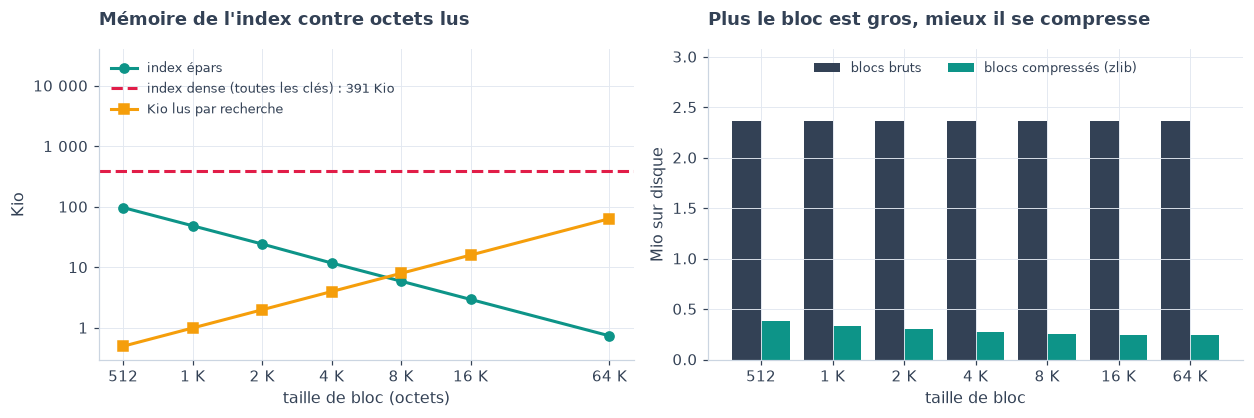

,bloc_octets,entrees_index,index_Kio,octets_lus_par_get,disque_Mio,compresse_Mio
0,512,5000,97.656,512,2.365,0.387
1,1024,2500,48.828,1024,2.365,0.330
2,2048,1250,24.414,2048,2.365,0.306
3,4096,607,11.855,4096,2.365,0.276
4,8192,304,5.938,8192,2.365,0.255
5,16384,152,2.969,16384,2.365,0.246
6,65536,38,0.742,65536,2.365,0.245


In [4]:
rows = []
for bb in [512, 1024, 2048, 4096, 8192, 16384, 65536]:
    t = S.SSTable(items, block_bytes=bb, bloom_bits_per_key=0)
    tc = S.SSTable(items, block_bytes=bb, bloom_bits_per_key=0, compress=True)
    idx_bytes = sum(len(k) + 8 for k in t.sparse_index)
    rows.append(dict(bloc_octets=bb, entrees_index=len(t.sparse_index), index_Kio=idx_bytes / 1024,
                     octets_lus_par_get=bb, disque_Mio=t.size_bytes / 2**20, compresse_Mio=tc.size_bytes / 2**20))
blk = pd.DataFrame(rows)
dense = len(items) * (12 + 8) / 1024
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
ax = axes[0]
ax.plot(blk.bloc_octets, blk.index_Kio, "o-", color=TEAL, label="index épars")
ax.axhline(dense, color=ROSE, ls="--", label=f"index dense (toutes les clés) : {dense:.0f} Kio")
ax.plot(blk.bloc_octets, blk.octets_lus_par_get / 1024, "s-", color=AMBER, label="Kio lus par recherche")
ax.set_xscale("log", base=2); ax.set_yscale("log"); S.plain_log_ticks(ax)
ax.set_xticks(blk.bloc_octets, [f"{b // 1024} K" if b >= 1024 else str(b) for b in blk.bloc_octets])
ax.minorticks_off(); ax.set_ylim(0.3, 40000)
ax.set_xlabel("taille de bloc (octets)"); ax.set_ylabel("Kio")
ax.set_title("Mémoire de l'index contre octets lus")
ax.legend(fontsize=8.5, loc="upper left")
ax = axes[1]
x = np.arange(len(blk))
ax.bar(x - 0.2, blk.disque_Mio, 0.4, color=SLATE, label="blocs bruts")
ax.bar(x + 0.2, blk.compresse_Mio, 0.4, color=TEAL, label="blocs compressés (zlib)")
ax.set_xticks(x, [f"{b // 1024} K" if b >= 1024 else str(b) for b in blk.bloc_octets])
ax.set_xlabel("taille de bloc"); ax.set_ylabel("Mio sur disque")
ax.set_title("Plus le bloc est gros, mieux il se compresse")
ax.set_ylim(0, blk.disque_Mio.max() * 1.3)
ax.legend(fontsize=8.5, loc="upper center", ncol=2)
finish(fig)
plt.show()
blk

Avec des blocs de 4 Kio, l'index épars compte une trentaine de fois moins d'entrées que
de clés : il tient sans peine en mémoire, même pour une très grosse table, et une recherche
lit un seul bloc. La compression gagne à des blocs plus grands, car le compresseur
exploite davantage de répétitions.

> **À retenir.** Une SSTable est un segment trié, sans doublon. Le tri permet un index
> **épars** (une clé par bloc), la compression par bloc et les parcours par intervalle.

## 2. Construire des SSTables : memtable et WAL (section *Constructing and maintaining SSTables*)

**Le problème.** Les écritures arrivent dans un ordre quelconque, or une SSTable doit
être triée. Réécrire tout le fichier à chaque insertion serait ruineux.

**La solution** combine un journal et un fichier trié :

1. une écriture va d'abord dans une structure **ordonnée en mémoire**, la **memtable**
   (arbre rouge-noir, skip list, trie...) ;
2. quand la memtable dépasse un seuil (quelques Mo), on l'écrit sur disque **dans
   l'ordre** : c'est la SSTable la plus récente. Pendant ce temps, une nouvelle memtable
   reçoit les écritures ;
3. pour lire, on cherche dans la memtable, puis dans les SSTables de la plus récente à
   la plus ancienne ;
4. en tâche de fond, on fusionne et compacte les SSTables (sections 3 et 5).

Une panne ferait perdre la memtable : chaque écriture est donc aussi **ajoutée à un
journal sur disque**, le *write-ahead log* (WAL), non trié, qui ne sert qu'à
reconstruire la memtable au redémarrage. Il est vidé à chaque écriture de la memtable.
Ce principe, publié en 1996 sous le nom de *Log-Structured Merge-Tree* (**LSM-tree**),
est celui de LevelDB, RocksDB, Cassandra et HBase, inspirés de Bigtable (qui a introduit
les termes SSTable et memtable).

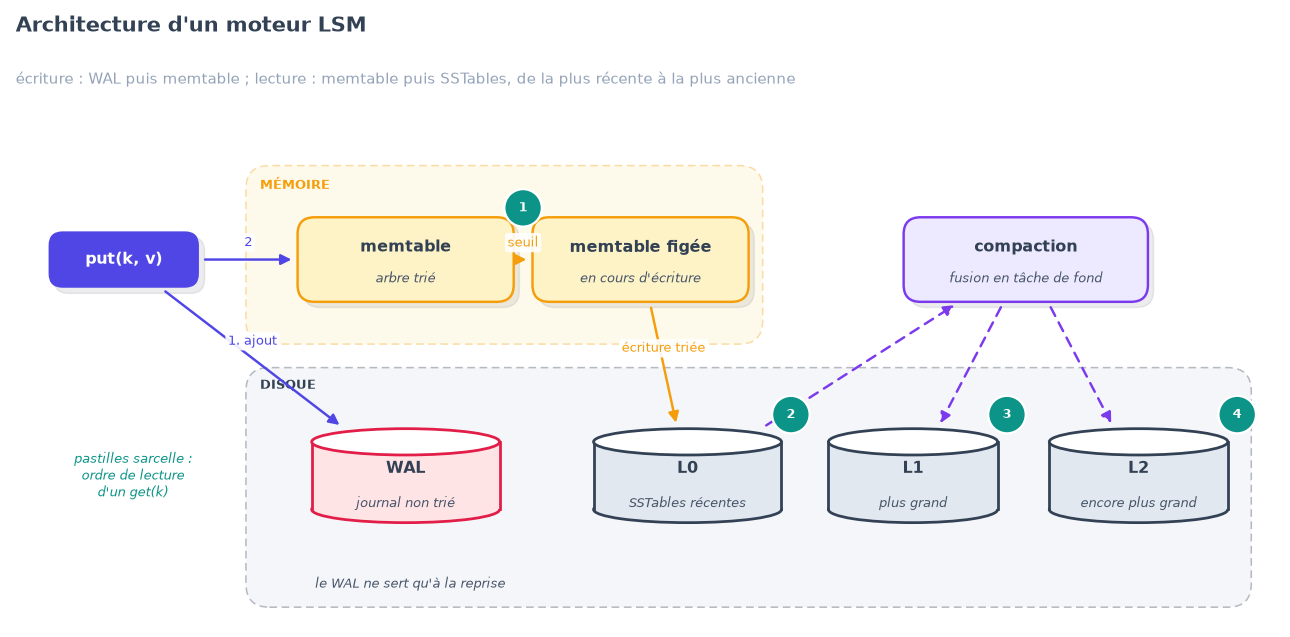

In [5]:
d = Diagram(13.5, 5.6, title="Architecture d'un moteur LSM",
            subtitle="écriture : WAL puis memtable ; lecture : memtable puis SSTables, de la plus récente à la plus ancienne")
d.box("w", 1.2, 3.9, "put(k, v)", color=INDIGO, kind="tag", w=1.6, h=0.6)
d.group(2.5, 3.0, 8.0, 4.9, "mémoire", color=AMBER)
d.box("mem", 4.2, 3.9, "memtable", sub="arbre trié", color=AMBER, w=2.3)
d.box("imm", 6.7, 3.9, "memtable figée", sub="en cours d'écriture", color=AMBER, w=2.3)
d.group(2.5, 0.2, 13.2, 2.75, "disque", color=SLATE)
d.box("wal", 4.2, 1.6, "WAL", sub="journal non trié", color=ROSE, kind="db", w=2.0, h=1.0)
d.box("l0", 7.2, 1.6, "L0", sub="SSTables récentes", color=SLATE, kind="db", w=2.0, h=1.0)
d.box("l1", 9.6, 1.6, "L1", sub="plus grand", color=SLATE, kind="db", w=1.8, h=1.0)
d.box("l2", 12.0, 1.6, "L2", sub="encore plus grand", color=SLATE, kind="db", w=1.9, h=1.0)
d.box("cmp", 10.8, 3.9, "compaction", sub="fusion en tâche de fond", color=VIOLET, w=2.6)
d.arrow("w", "mem", "2", color=INDIGO)
d.arrow("w", "wal", "1. ajout", color=INDIGO)
d.arrow("mem", "imm", "seuil", color=AMBER)
d.arrow("imm", "l0", "écriture triée", color=AMBER)
d.arrow("cmp", "l1", style="dashed", color=VIOLET)
d.arrow("cmp", "l2", style="dashed", color=VIOLET)
d.arrow("l0", "cmp", style="dashed", color=VIOLET)
for j, (x, y) in enumerate([(5.45, 4.45), (8.3, 2.25), (10.6, 2.25), (13.05, 2.25)], 1):
    d.badge(x, y, str(j), color=TEAL)
d.note(1.3, 1.6, "pastilles sarcelle :\nordre de lecture\nd'un get(k)", color=TEAL, fontsize=8.5)
d.note(4.25, 0.45, "le WAL ne sert qu'à la reprise", fontsize=8.5)
d.show()

Le WAL n'est **jamais lu** en fonctionnement normal : une lecture consulte la memtable
puis les SSTables de la plus récente à la plus ancienne (pastilles numérotées). Faisons tourner le
moteur sans compaction (`strategy="none"`) sur 30 000 écritures de clés aléatoires : la
memtable de 64 Kio est écrite sur disque régulièrement.

In [6]:
lsm = S.LSMTree(memtable_bytes=64 * 1024, strategy="none")
keys = S.zipf_keys(30_000, 10_000, s=0.7, seed=1)
for n, i in enumerate(keys):
    lsm.put(S.kv_key(int(i)), S.kv_value(int(i), n))
hist = pd.DataFrame(lsm.history)
print(f"{lsm.stats['flushes']} écritures de memtable, {lsm.n_sstables()} SSTables sur disque,",
      f"WAL actuel : {len(lsm.wal) / 1024:.0f} Kio, memtable : {len(lsm.memtable)} clés")

48 écritures de memtable, 48 SSTables sur disque, WAL actuel : 1 Kio, memtable : 10 clés


**Reprise après panne.** Simulons une panne : la memtable disparaît, les SSTables et le
WAL survivent. On rejoue le WAL ; puis on recommence avec un WAL dont le dernier
enregistrement n'a été écrit qu'à moitié (panne pendant l'ajout). Grâce aux sommes de
contrôle, l'enregistrement incomplet est simplement ignoré : cette écriture-là n'avait
pas été confirmée au client.

In [7]:
derniere = list(lsm.memtable)[-1]
complet = lsm.crash()
coupe = lsm.crash(keep_wal_bytes=len(lsm.wal) - 7)
pd.DataFrame({"WAL intact": [complet.replayed, complet.get(derniere) == lsm.get(derniere)],
              "WAL tronqué de 7 octets": [coupe.replayed, coupe.get(derniere) == lsm.get(derniere)]},
             index=["enregistrements rejoués", "dernière écriture retrouvée"])

,WAL intact,WAL tronqué de 7 octets
enregistrements rejoués,10,9
dernière écriture retrouvée,True,False


> **À retenir.** Un moteur LSM écrit d'abord dans un WAL (durabilité) et une memtable
> triée (en mémoire), puis vide la memtable en SSTable d'un seul trait. Les fichiers
> sur disque ne sont jamais modifiés : une panne au milieu d'une écriture de SSTable se
> répare en supprimant le fichier inachevé.

## 3. Fusionner des segments : le tri fusion (section *Constructing and maintaining SSTables*)

**Problème.** Sans compaction, les SSTables s'accumulent : 48 SSTables pour 30 000
écritures ci-dessus. Chaque lecture d'une clé absente doit potentiellement toutes les
consulter.

**Algorithme.** La fusion fonctionne comme l'étape de fusion du **tri fusion** : on lit
les fichiers d'entrée côte à côte, on compare la première clé de chacun, on copie la
plus petite en sortie et on avance. Si une clé apparaît dans plusieurs fichiers, on ne
garde que la valeur du segment **le plus récent**. La mémoire utilisée est minime (une
clé par fichier d'entrée, dans un tas de taille $k$) et le coût est
$O(N \log k)$ pour $N$ enregistrements et $k$ fichiers.

**Tombstones.** Une suppression est un enregistrement spécial qui masque les versions
plus anciennes. On peut l'oublier quand on fusionne dans le segment **le plus ancien** :
il n'y a plus rien à masquer en dessous.

In [8]:
recent = [("banane", "3"), ("cerise", None), ("fraise", "9")]
moyen = [("abricot", "1"), ("banane", "2"), ("datte", "5")]
ancien = [("abricot", "0"), ("banane", "1"), ("cerise", "4"), ("figue", "7")]
fusion = S.merge_runs([recent, moyen, ancien])
fusion_finale = S.merge_runs([recent, moyen, ancien], drop_tombstones=True)
toutes = sorted({k for run in (recent, moyen, ancien) for k, _ in run})


def montrer(run):
    dct = dict(run)
    return [("(tombstone)" if dct[k] is None else dct[k]) if k in dct else "" for k in toutes]


pd.DataFrame({"récent": montrer(recent), "moyen": montrer(moyen), "ancien": montrer(ancien),
              "fusion": montrer(fusion), "fusion dans le dernier niveau": montrer(fusion_finale)},
             index=toutes)

,récent,moyen,ancien,fusion,fusion dans le dernier niveau
abricot,,1,0,1,1
banane,3,2,1,3,3
cerise,(tombstone),,4,(tombstone),
datte,,5,,5,5
figue,,,7,7,7
fraise,9,,,9,9


`banane` prend la valeur du segment récent (3) ; `cerise` est masquée par son tombstone,
qui disparaît lui-même quand on fusionne dans le dernier niveau. Vérifions le coût
quasi linéaire de la fusion en faisant varier la taille et le nombre de segments.

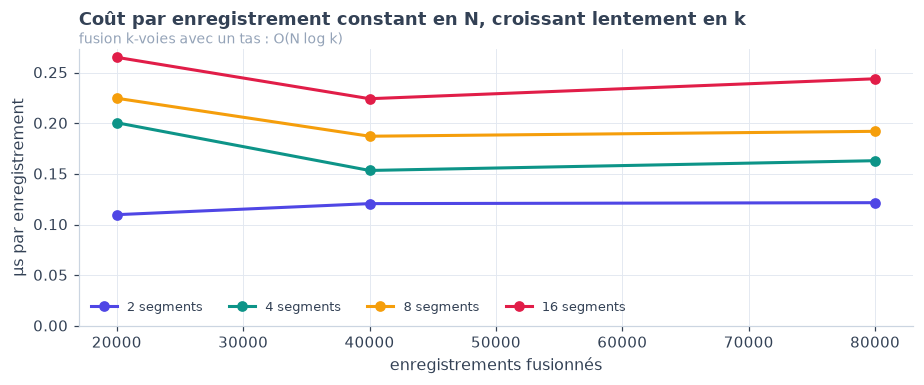

In [9]:
rows = []
rng = np.random.default_rng(0)
S.merge_runs([[(S.kv_key(i), "v") for i in range(20_000)]] * 2)  # échauffement (caches, allocateur)
for n_runs in [2, 4, 8, 16]:
    for total in [20_000, 40_000, 80_000]:
        runs = []
        for r in range(n_runs):
            ks = np.sort(rng.choice(200_000, size=total // n_runs, replace=False))
            runs.append([(S.kv_key(int(k)), "v") for k in ks])
        t0 = time.perf_counter()
        out = S.merge_runs(runs)
        rows.append(dict(segments=n_runs, enregistrements=total, sortie=len(out),
                         us_par_enregistrement=(time.perf_counter() - t0) / total * 1e6))
mg = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for (k, g), c in zip(mg.groupby("segments"), COLORS):
    ax.plot(g.enregistrements, g.us_par_enregistrement, "o-", color=c, label=f"{k} segments")
ax.set_ylim(bottom=0)
ax.set_xlabel("enregistrements fusionnés"); ax.set_ylabel("µs par enregistrement")
ax.set_title("Coût par enregistrement constant en N, croissant lentement en k")
subtitle(ax, "fusion k-voies avec un tas : O(N log k)")
ax.legend(ncol=4, fontsize=8.5)
plt.tight_layout(); plt.show()

Le coût par enregistrement ne dépend pas de la taille totale (fusion linéaire en $N$)
et n'augmente que modérément avec le nombre de segments (le facteur $\log k$ du tas).
C'est pour cela que la fusion peut tourner en continu en tâche de fond, sur des
fichiers bien plus gros que la mémoire.

> **À retenir.** Fusionner des SSTables, c'est l'étape de fusion du tri fusion : un
> passage séquentiel, peu de mémoire, la version la plus récente gagne et les
> tombstones meurent dans le dernier niveau.